## Recurring Taxi Demand and Peak Sources (Flag 7)

### Dataset Overview
A Porto Taxi case containing 715 taxi requests from six widely spaced observation dates. The demand table records request time, peak period, pickup and dropoff locations, request source, and taxi-stand identity; linked GPS points provide each trip trajectory; the stand table provides stand locations and regions.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze recurring patterns and longer-term changes in taxi demand across the city.

Role: Urban taxi-demand analyst


Category: Citywide demand periodicity, peak spatial structure, and longitudinal change

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "taxi_demand.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What recurring within-day pattern does citywide taxi demand exhibit across the supplied observation dates?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

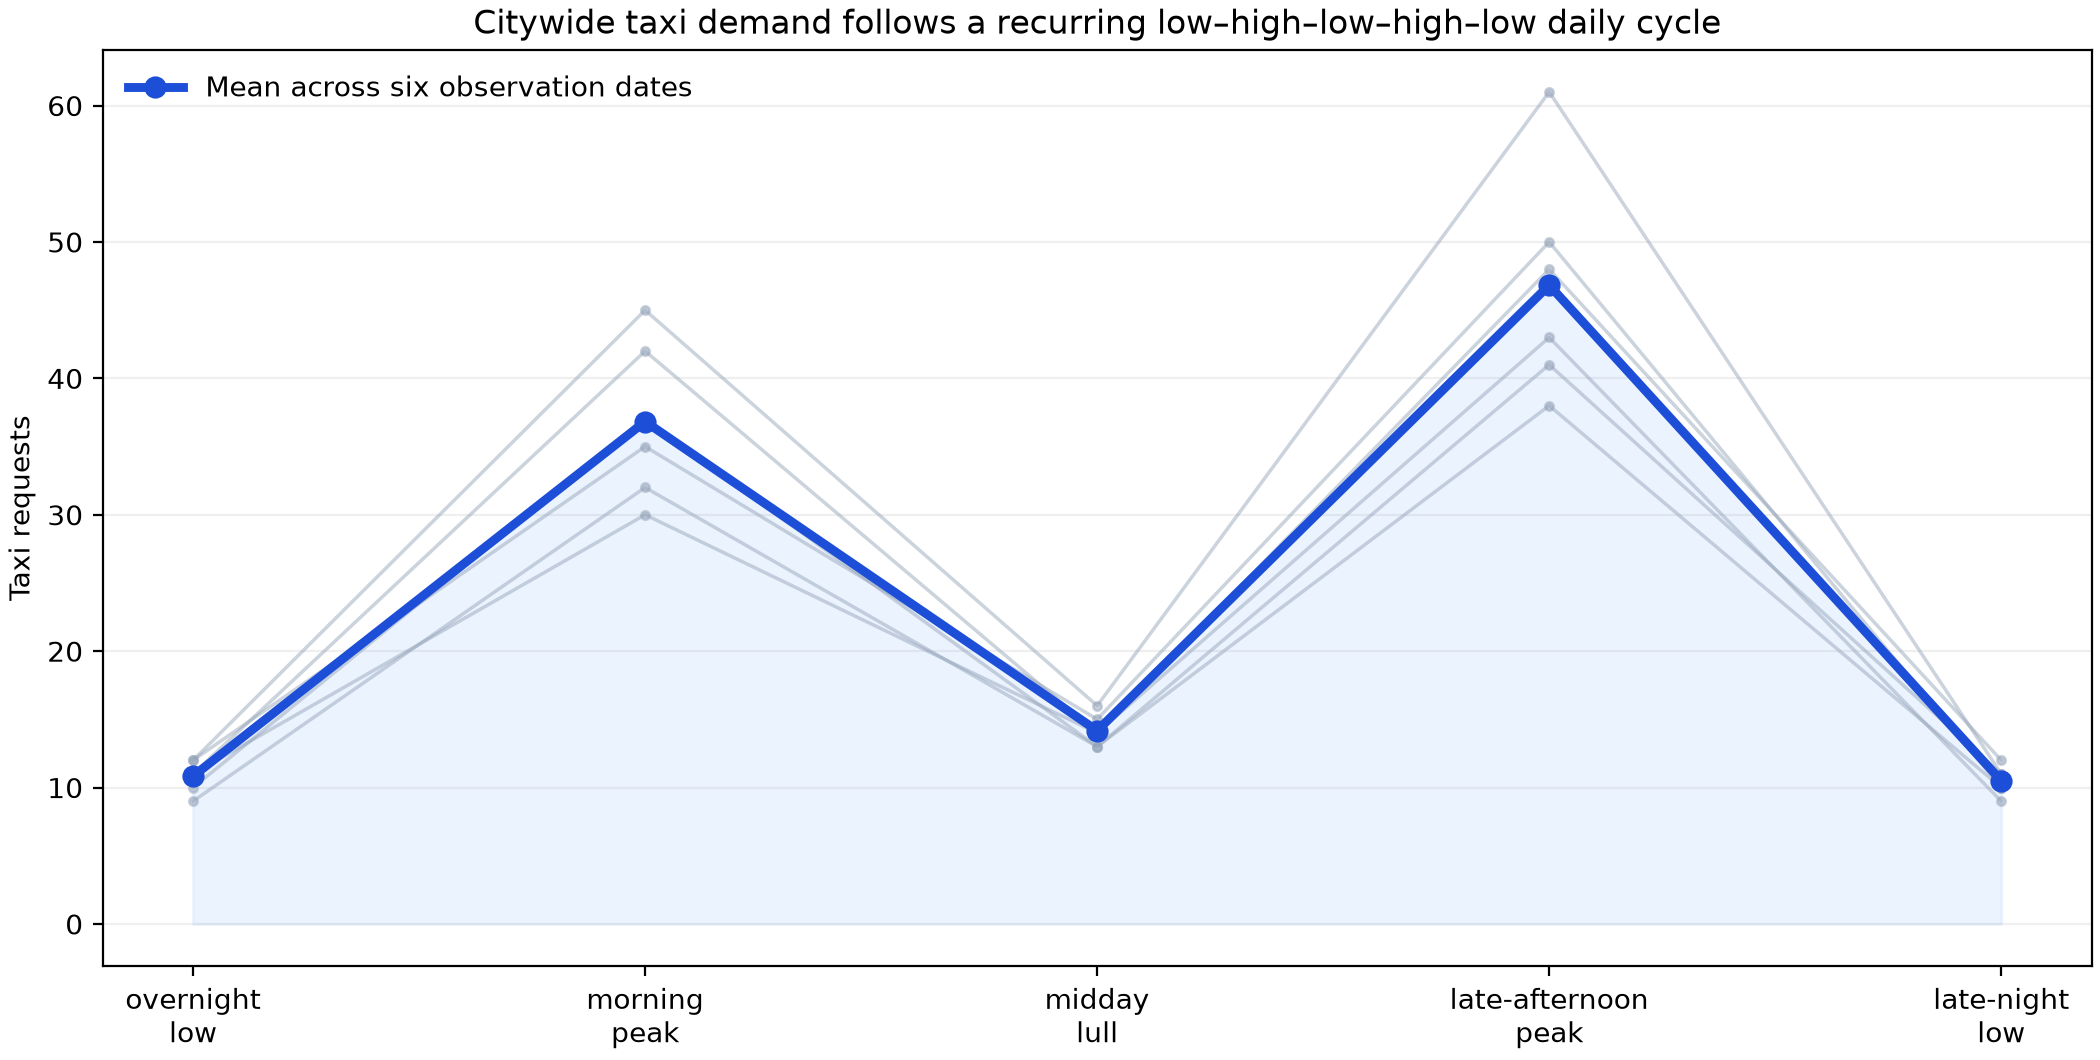

In [ ]:
d=df.copy(); d['request_time']=pd.to_datetime(d.request_time); print(d.groupby(['service_date','time_period']).size().unstack(fill_value=0))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/citywide_temporal_cycle.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "citywide_temporal_demand_cycle",
  "insight": "Citywide taxi demand follows a recurring low–high–low–high–low daily cycle, with a morning peak, a midday lull, a larger late-afternoon peak, and low demand overnight and late at night.",
  "plot": {
    "plot_type": "multi_day_temporal_profile_line_chart",
    "file": "visualizations/citywide_temporal_cycle.png",
    "title": "Recurring Citywide Taxi Demand Cycle",
    "description": "Thin lines show the five-period demand profile for each observation date; the blue line is the cross-date mean."
  },
  "question": "What recurring within-day pattern does citywide taxi demand exhibit across the supplied observation dates?",
  "code": "d=df.copy(); d['request_time']=pd.to_datetime(d.request_time); print(d.groupby(['service_date','time_period']).size().unstack(fill_value=0))",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "trajectory_id"
  ]
}

### **Question 2**: How do the spatial distributions of taxi requests and linked trajectories differ between the morning and late-afternoon demand peaks?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

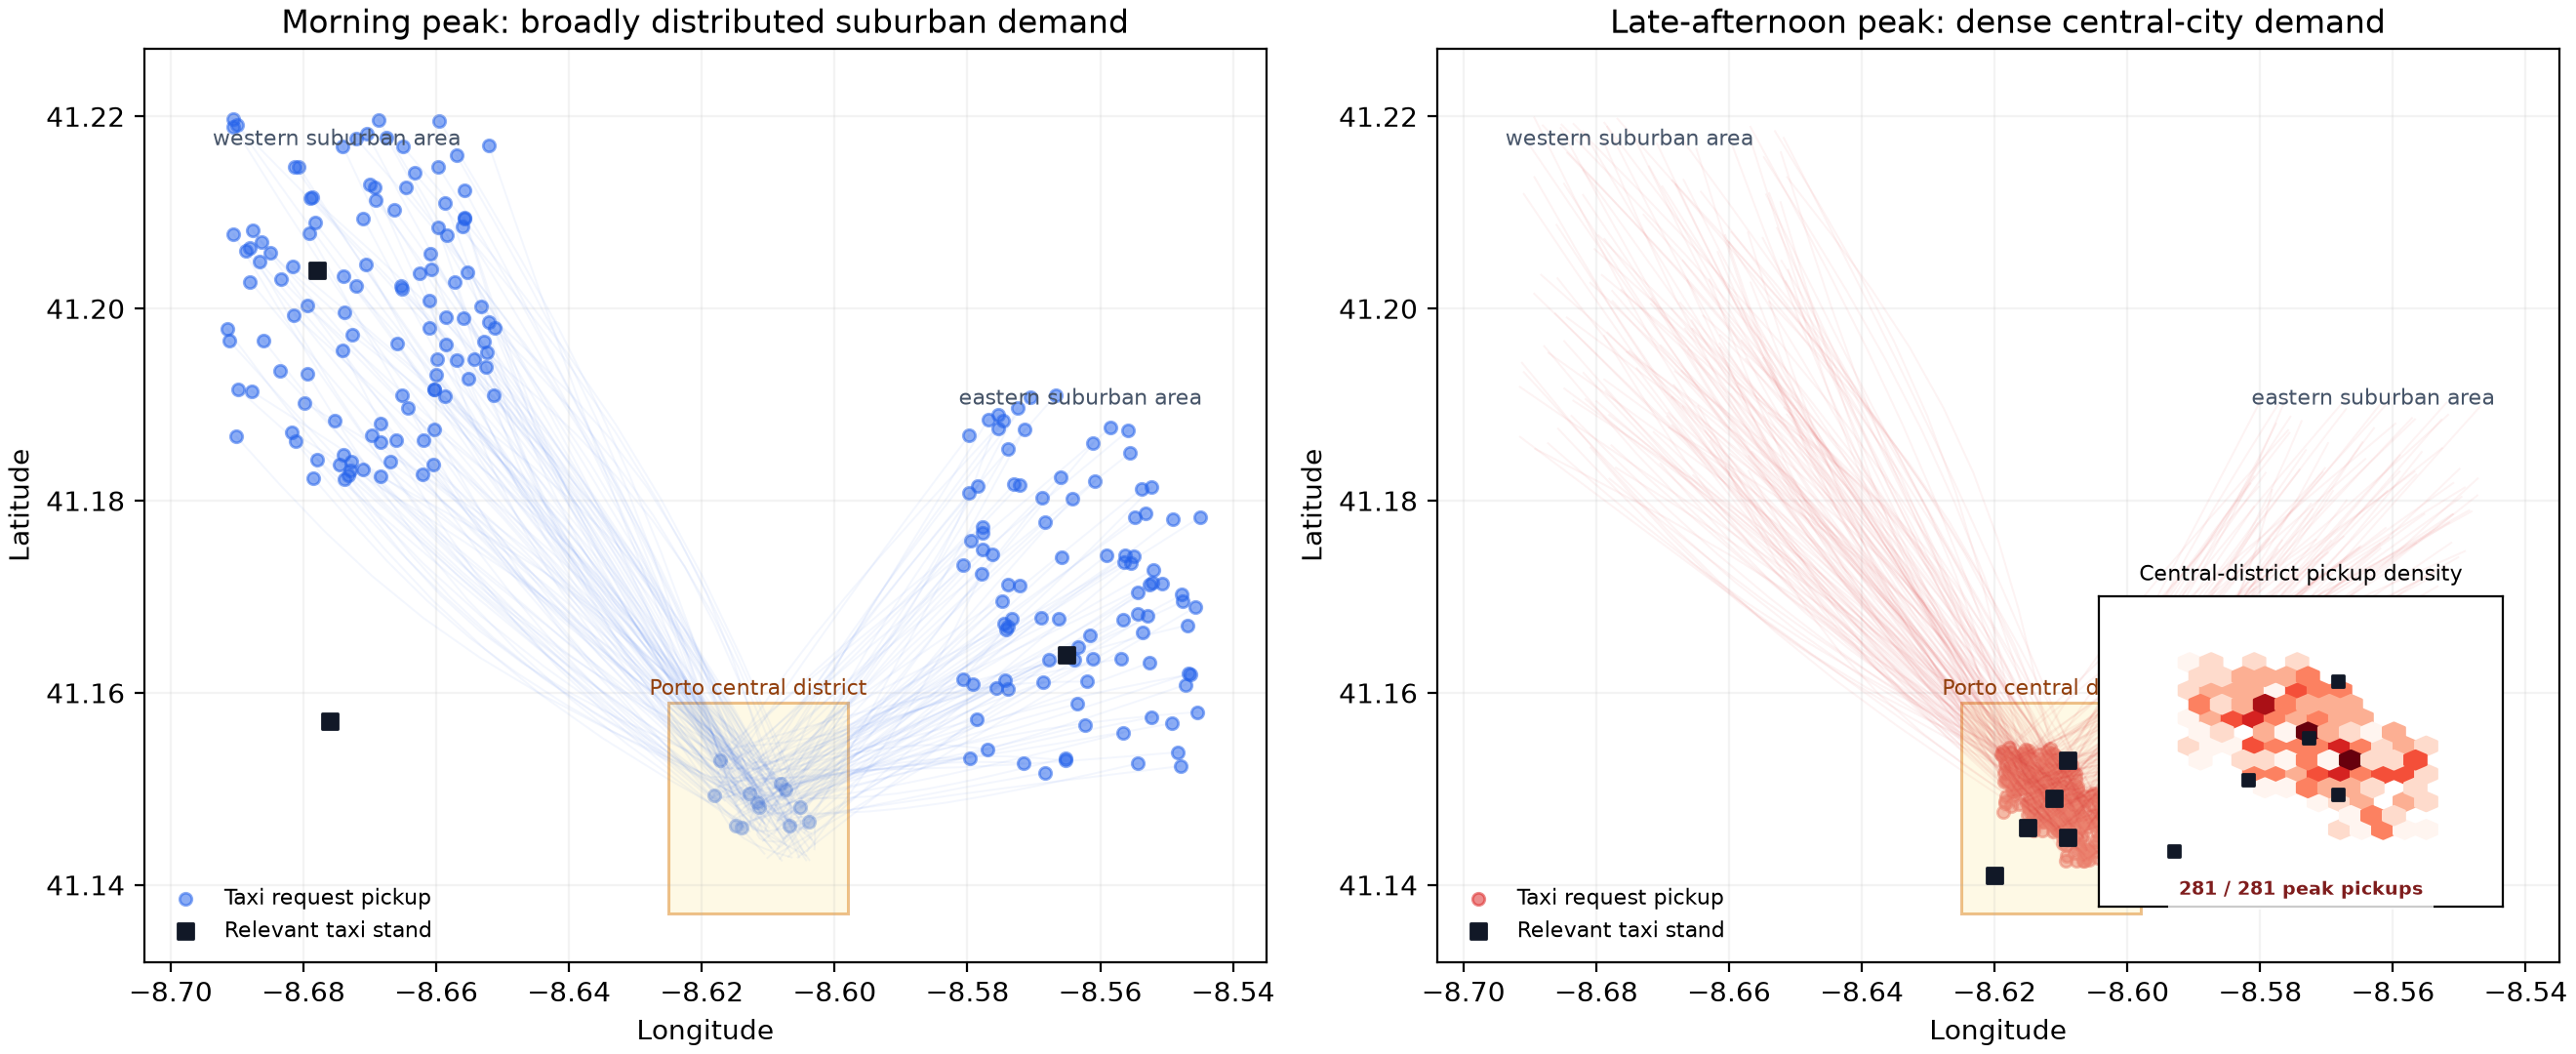

In [ ]:
d=df.copy(); p=pd.read_csv(user_dataset_path); print(d[d.time_period.isin(['morning_peak','late_afternoon_peak'])].groupby(['time_period','origin_region']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/peak_spatial_demand_and_trajectories.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatiotemporal_peak_structure",
  "insight": "The two daily peaks have different spatial structures: morning-peak demand is broadly distributed across the western and eastern suburban service areas, whereas late-afternoon demand is densely concentrated in Porto's central district.",
  "plot": {
    "plot_type": "paired_peak_demand_maps_with_trajectories",
    "file": "visualizations/peak_spatial_demand_and_trajectories.png",
    "title": "Spatial Structure of the Two Daily Demand Peaks",
    "description": "Pickup locations and their linked trip trajectories contrast the broad suburban morning peak with the compact central late-afternoon peak."
  },
  "question": "How do the spatial distributions of taxi requests and linked trajectories differ between the morning and late-afternoon demand peaks?",
  "code": "d=df.copy(); p=pd.read_csv('trajectory_points.csv'); print(d[d.time_period.isin(['morning_peak','late_afternoon_peak'])].groupby(['time_period','origin_region']).size())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "gps_position",
    "trajectory_id",
    "stand_position"
  ]
}

### **Question 3**: Does the recurring daily cycle remain stable across the longer observation period, and how do the two peak totals change across dates?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

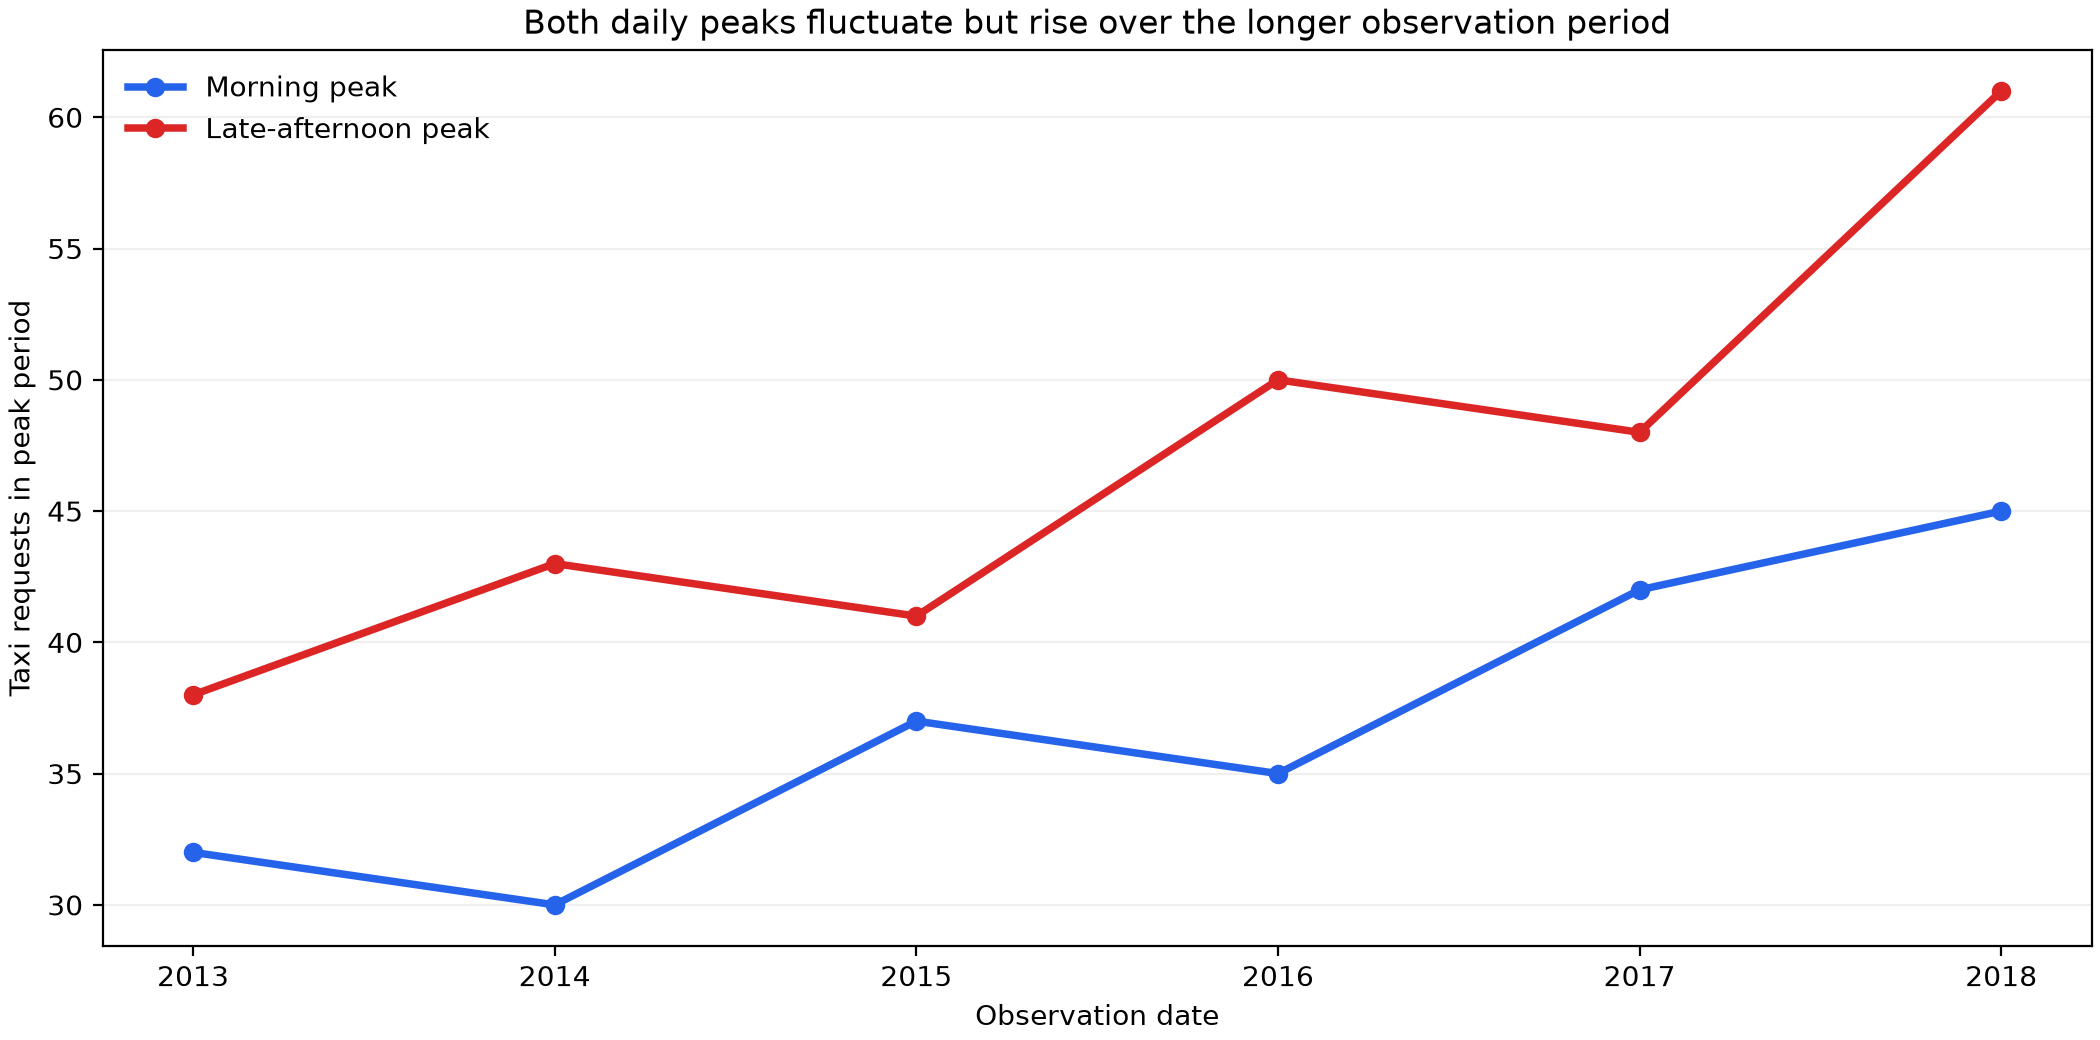

In [ ]:
d=df.copy(); print(d[d.time_period.isin(['morning_peak','late_afternoon_peak'])].groupby(['service_date','time_period']).size().unstack())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/peak_demand_over_observation_dates.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "longitudinal_peak_demand_change",
  "insight": "The low–high–low–high–low cycle recurs across all observation dates, but the two daily peak totals fluctuate while trending upward over the longer observation period.",
  "plot": {
    "plot_type": "two_peak_time_series_line_chart",
    "file": "visualizations/peak_demand_over_observation_dates.png",
    "title": "Peak Demand Across Observation Dates",
    "description": "The morning and late-afternoon peak totals are shown for six widely spaced observation dates."
  },
  "question": "Does the recurring daily cycle remain stable across the longer observation period, and how do the two peak totals change across dates?",
  "code": "d=df.copy(); print(d[d.time_period.isin(['morning_peak','late_afternoon_peak'])].groupby(['service_date','time_period']).size().unstack())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "trajectory_id"
  ]
}

### **Question 4**: After comparing the designated stands with the combined total of all other observed stands, which fixed stands account for each peak's growth, and do the growing morning and late-afternoon stands overlap?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

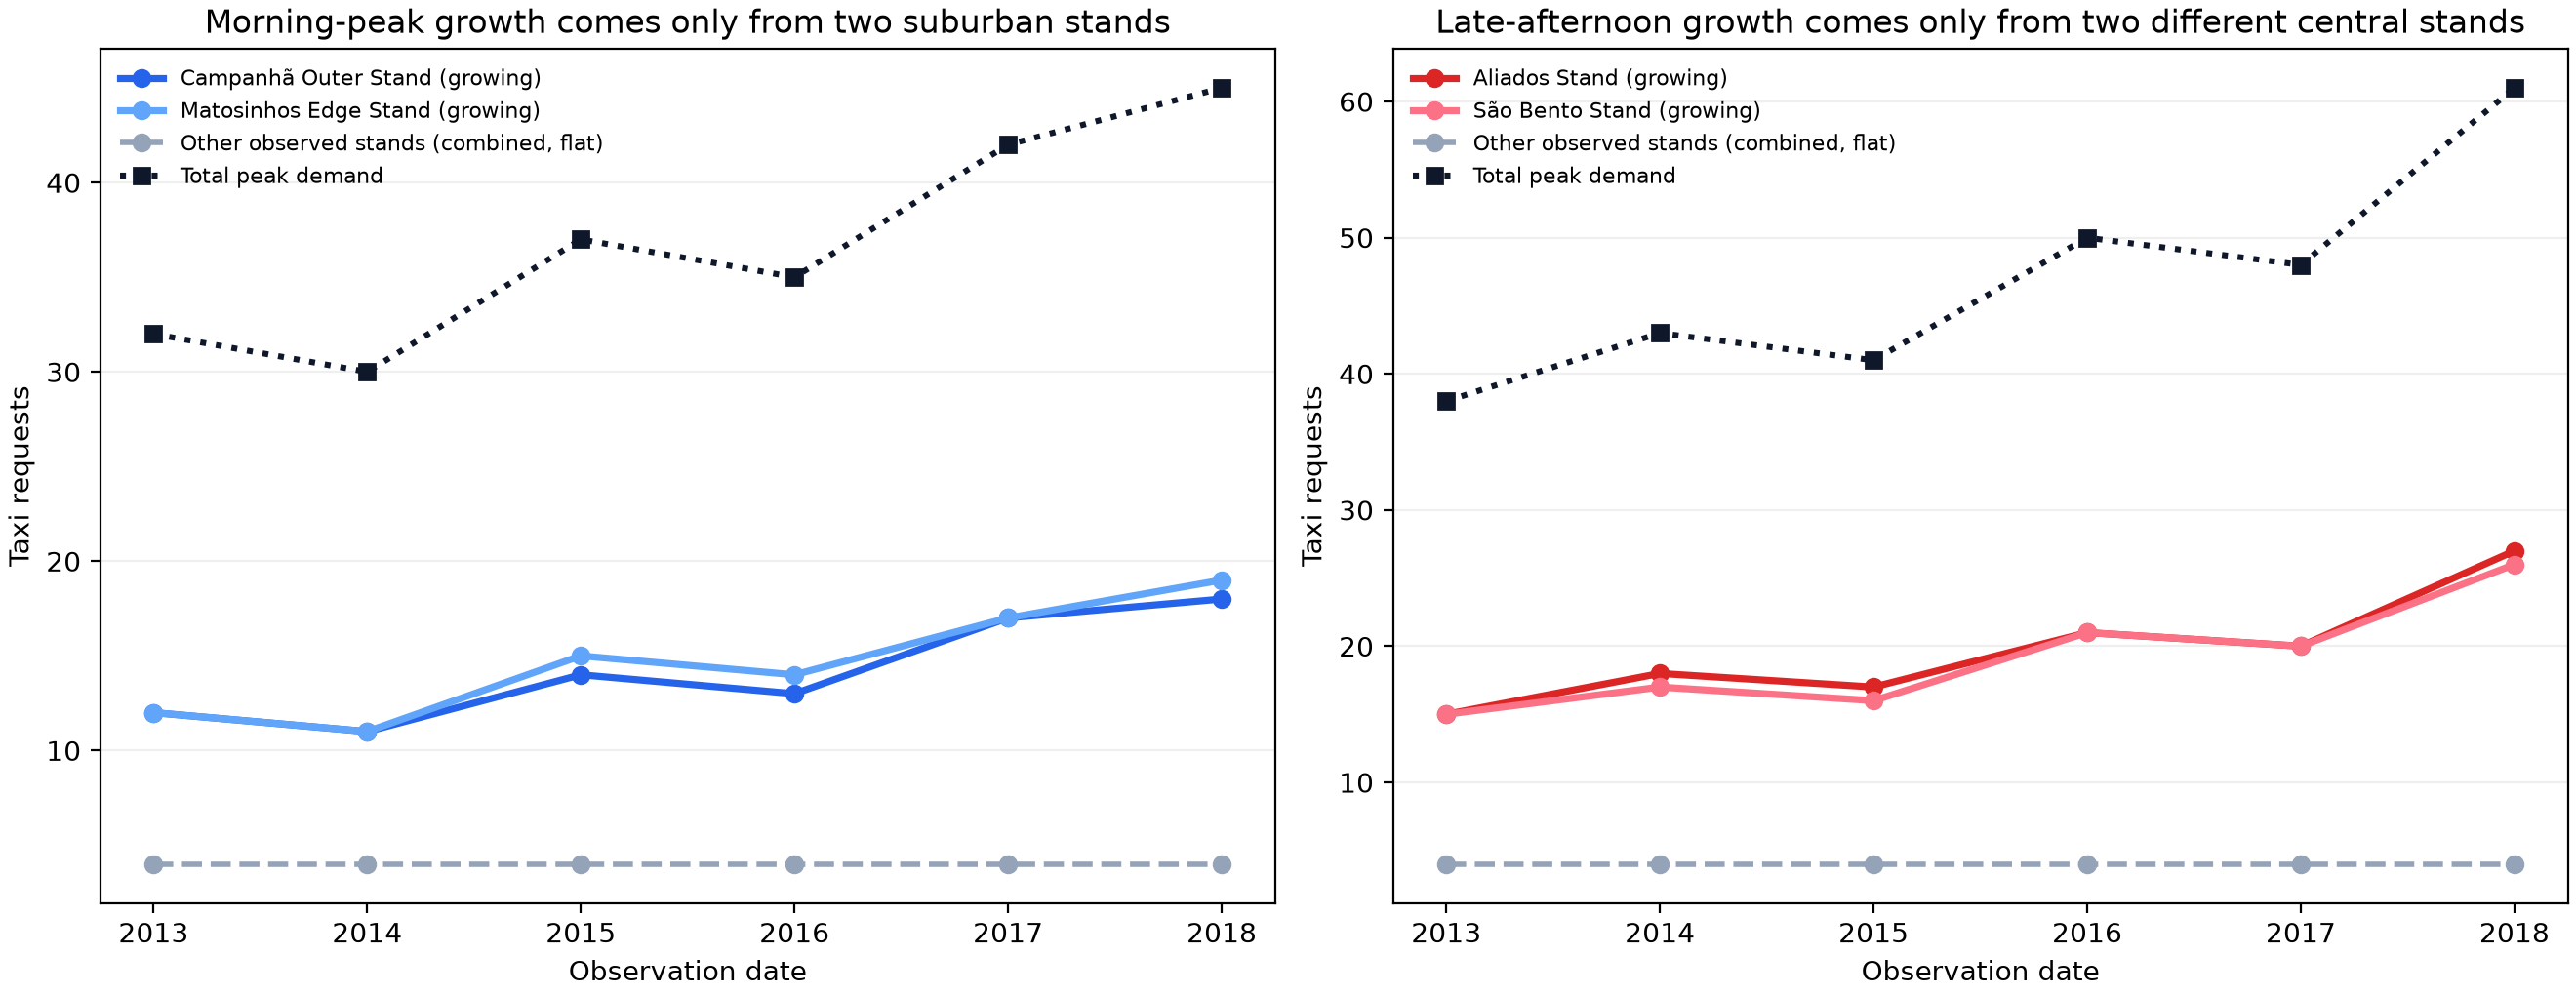

In [ ]:
d=df.copy(); x=d[(d.request_source=='taxi_stand') & d.time_period.isin(['morning_peak','late_afternoon_peak'])]; print(x.groupby(['service_date','time_period','origin_stand_name']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/stand_sources_of_peak_growth.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "region_specific_taxi_stand_growth",
  "insight": "Over the longer observation period, morning-peak growth comes from two fixed stands, whereas late-afternoon growth comes from two different fixed stands.",
  "plot": {
    "plot_type": "growing_stands_vs_combined_other_stands",
    "file": "visualizations/stand_sources_of_peak_growth.png",
    "title": "Peak Growth from Designated Stands versus All Other Stands",
    "description": "Each panel compares the two growing stands, the combined total of every other observed stand, and total peak demand. The combined comparison group remains flat."
  },
  "question": "After comparing the designated stands with the combined total of all other observed stands, which fixed stands account for each peak's growth, and do the growing morning and late-afternoon stands overlap?",
  "code": "d=df.copy(); x=d[(d.request_source=='taxi_stand') & d.time_period.isin(['morning_peak','late_afternoon_peak'])]; print(x.groupby(['service_date','time_period','origin_stand_name']).size())",
  "insight_type": "factor_relationship",
  "insight_value": {
    "evidence": "Morning-peak growth comes from the fixed Matosinhos Edge and Campanhã Outer suburban stands, while the other observed morning stands remain flat; late-afternoon growth comes from the fixed Aliados and São Bento central stands, while its other observed stands remain flat."
  },
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "origin_stand",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 7)

Taxi demand repeatedly follows a low–high–low–high–low daily cycle across the six supplied dates. The morning and late-afternoon peaks have contrasting spatial structures—broad suburban demand in the morning and compact central demand later in the day—and both peak totals fluctuate but rise over time. Their growth comes from distinct, fixed groups of suburban versus central taxi stands.